In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings

warnings.filterwarnings("ignore")
plt.style.use('seaborn-v0_8-darkgrid')

# Load the dataset
df = pd.read_csv('./data/raw/Dataset.csv')
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")
df.head(3)

Dataset loaded successfully with 8790 rows and 10 columns.


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"


In [7]:
# Drop rows where 'date_added' is missing
df_clean = df.dropna(subset=['date_added']).copy()

# Convert 'date_added' to datetime
df_clean['date_added'] = pd.to_datetime(df_clean['date_added'].str.strip())

# Set date_added as the index and sort it
df_clean.set_index('date_added', inplace=True)
df_clean.sort_index(inplace=True)

# Resample the data to count the number of releases per month ('ME' = Month End)
# We will focus on data from 2014 onwards, as early Netflix streaming data is sparse
monthly_releases = df_clean.resample('ME').size()
monthly_releases = monthly_releases[monthly_releases.index.year >= 2014]

print("Time-based features")
print(monthly_releases.tail())

Time-based features
date_added
2021-05-31    132
2021-06-30    207
2021-07-31    257
2021-08-31    178
2021-09-30    183
Freq: ME, dtype: int64


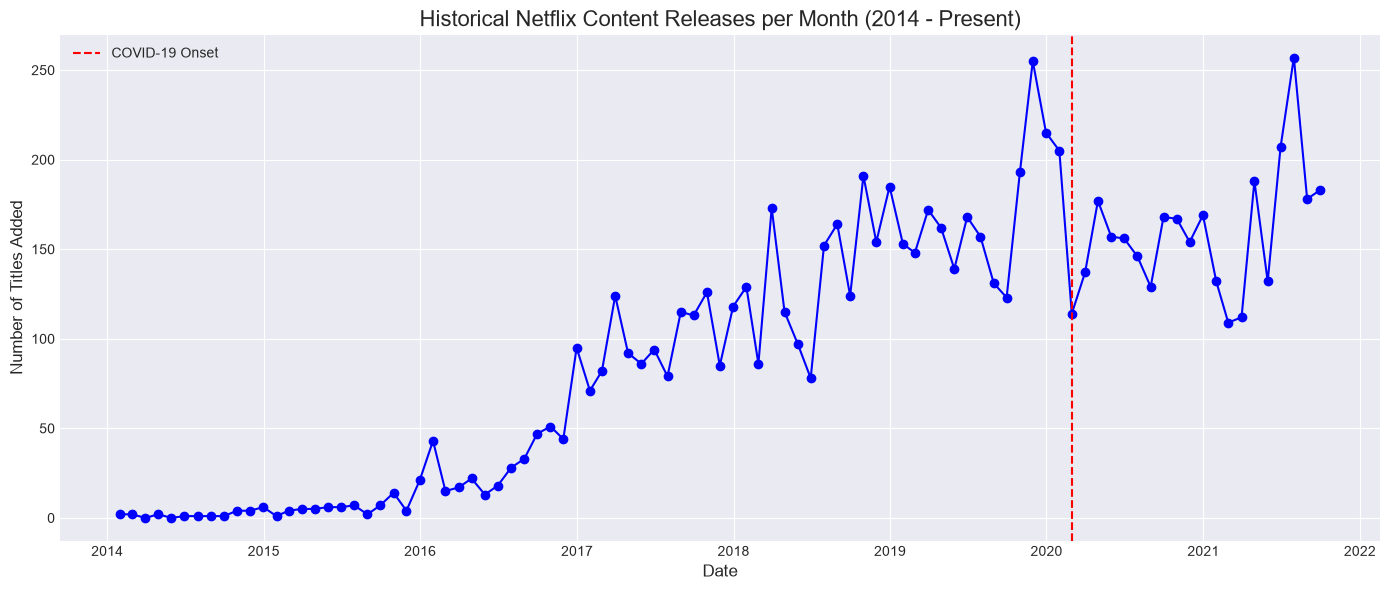

In [8]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_releases.index, monthly_releases.values, marker='o', linestyle='-', color='b')
plt.title('Historical Netflix Content Releases per Month (2014 - Present)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Titles Added', fontsize=12)
plt.axvline(pd.to_datetime('2020-03-01'), color='r', linestyle='--', label='COVID-19 Onset')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Split data 80%/20%
train_size = int(len(monthly_releases) * 0.8)
train, test = monthly_releases.iloc[:train_size], monthly_releases.iloc[train_size:]

print(f"Training data points: {len(train)} | Testing data points: {len(test)}")

# Define and fit the SARIMA model
# Order (p,d,q) = (1,1,1) for trend, Seasonal Order (P,D,Q,s) = (1,1,1,12) for yearly seasonality
model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
fitted_model = model.fit(disp=False)

print(fitted_model.summary().tables[1])

Training data points: 74 | Testing data points: 19
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1378      0.225      0.611      0.541      -0.304       0.580
ma.L1         -0.7816      0.128     -6.106      0.000      -1.032      -0.531
ar.S.L12       0.0452      0.442      0.102      0.919      -0.822       0.912
ma.S.L12      -0.5363      0.422     -1.270      0.204      -1.364       0.291
sigma2       722.4455    118.563      6.093      0.000     490.066     954.824


Model Evaluation -> RMSE: 55.50 | MAE: 45.29


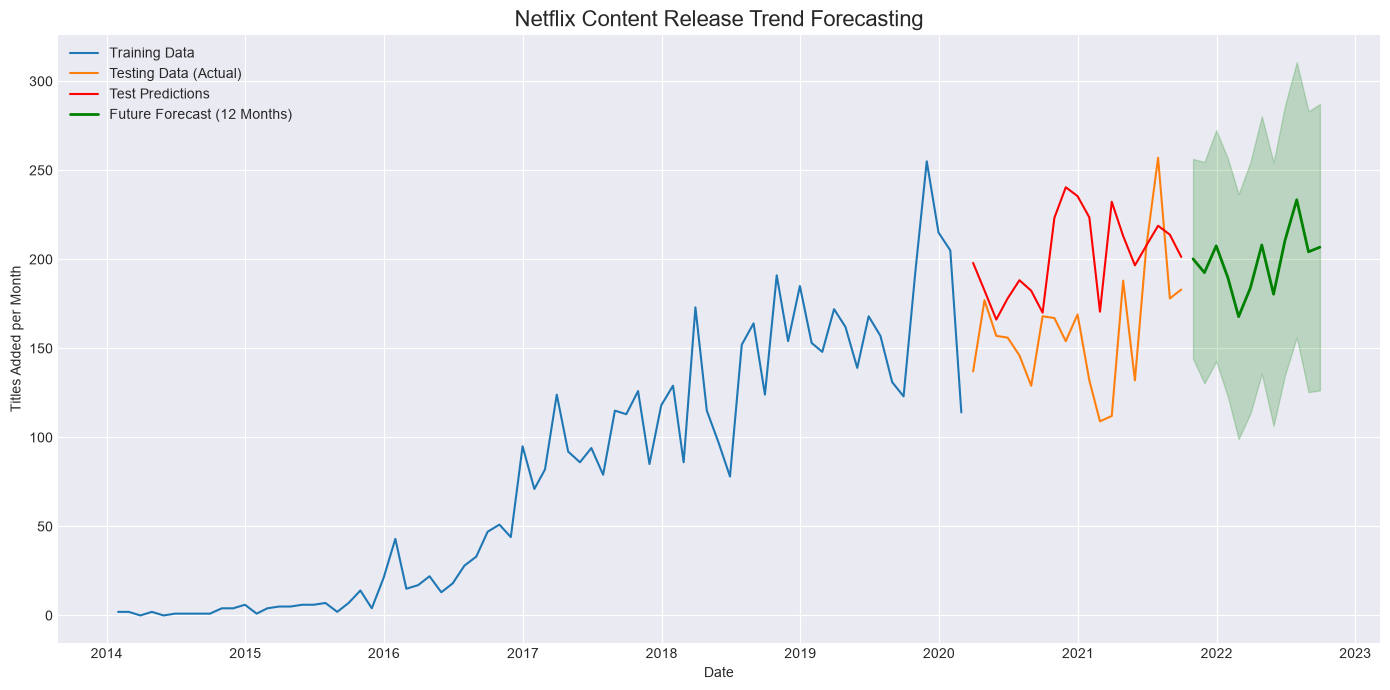

In [10]:
# Generate predictions for the test set
test_predictions = fitted_model.predict(start=test.index[0], end=test.index[-1], dynamic=False)

# Evaluate the model
rmse = np.sqrt(mean_squared_error(test, test_predictions))
mae = mean_absolute_error(test, test_predictions)
print(f"Model Evaluation -> RMSE: {rmse:.2f} | MAE: {mae:.2f}")

# Generate Future Forecast
final_model = SARIMAX(monthly_releases, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
future_forecast = final_model.get_forecast(steps=12)
forecast_mean = future_forecast.predicted_mean
forecast_ci = future_forecast.conf_int()

# Plot the final results
plt.figure(figsize=(14, 7))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Testing Data (Actual)')
plt.plot(test.index, test_predictions, color='red', label='Test Predictions')
plt.plot(forecast_mean.index, forecast_mean, color='green', label='Future Forecast (12 Months)', linewidth=2)

# Shade the confidence interval
plt.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='green', alpha=0.2)

plt.title('Netflix Content Release Trend Forecasting', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Titles Added per Month')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()